In [1]:
import citylearn
print(f"CityLearn version: {citylearn.__version__}")

CityLearn version: 3.0.2


In [2]:
import pandas as pd

# Citylearn Package Understanding

In [3]:
from citylearn.citylearn import CityLearnEnv
from citylearn.agents.base import BaselineAgent

env = CityLearnEnv(
    "citylearn_challenge_2023_phase_2_local_evaluation",
    central_agent=True,
)
agent = BaselineAgent(env)

observations, info = env.reset()
terminated = truncated = False

while not (terminated or truncated):
    actions = agent.predict(observations)
    observations, reward, terminated, truncated, info = env.step(actions)

print(env.evaluate()[["name", "cost_function", "value"]])

INFO:root:The dataset names DNE in cache. Will download from citylearn-project/CityLearn/tree/v3.0.2 GitHub repository and write to C:\Users\DELL\AppData\Local\citylearn-project\citylearn\Cache\v3.0.2\dataset_names.json. Next time DataSet.get_dataset_names is called, it will read from cache unless DataSet.clear_cache is run first.
INFO:root:The citylearn_challenge_2023_phase_2_local_evaluation dataset DNE in cache/local roots. Will download from citylearn-project/CityLearn/tree/v3.0.2 GitHub repository and write to C:\Users\DELL\AppData\Local\citylearn-project\citylearn\Cache\v3.0.2\datasets. Next time DataSet.get_dataset('citylearn_challenge_2023_phase_2_local_evaluation') is called, it will read from cache unless DataSet.clear_cache is run first.
d:\Conda\envs\citylearn\Lib\site-packages\gymnasium\spaces\box.py:130: UserWarning: WARN: Box bound precision lowered by casting to float32
  gym.logger.warn(f"Box bound precision lowered by casting to {self.dtype}")


          name                                  cost_function     value
0     District                          all_time_peak_average  1.000000
1     District        annual_normalized_unserved_energy_total  0.018316
2     District                         carbon_emissions_total  1.000000
3     District                                     cost_total  1.000000
4     District            daily_one_minus_load_factor_average  1.000000
..         ...                                            ...       ...
64  Building_3                   discomfort_hot_delta_maximum  3.733675
65  Building_3                   discomfort_hot_delta_average  0.081082
66  Building_3        one_minus_thermal_resilience_proportion  0.133333
67  Building_3  power_outage_normalized_unserved_energy_total  0.637254
68  Building_3        annual_normalized_unserved_energy_total  0.018077

[69 rows x 3 columns]


# Observations

In [4]:
observations, _ = env.reset()

for name, value in list(zip(env.observation_names[0], observations[0])):
    print(f"{name}: {value}")

day_type: 5
hour: 1
outdoor_dry_bulb_temperature: 24.65999984741211
outdoor_dry_bulb_temperature_predicted_1: 24.9106388092041
outdoor_dry_bulb_temperature_predicted_2: 38.415958404541016
outdoor_dry_bulb_temperature_predicted_3: 27.61146354675293
diffuse_solar_irradiance: 0.0
diffuse_solar_irradiance_predicted_1: 54.62592697143555
diffuse_solar_irradiance_predicted_2: 116.84288787841797
diffuse_solar_irradiance_predicted_3: 0.0
direct_solar_irradiance: 0.0
direct_solar_irradiance_predicted_1: 143.3243408203125
direct_solar_irradiance_predicted_2: 1020.756103515625
direct_solar_irradiance_predicted_3: 0.0
carbon_intensity: 0.4024883508682251
indoor_dry_bulb_temperature: 23.098651885986328
non_shiftable_load: 0.3568393290042877
solar_generation: 0.0
dhw_storage_soc: 0.0
electrical_storage_soc: 0.20000000298023224
net_electricity_consumption: 0.6778813600540161
electricity_pricing: 0.028929999098181725
electricity_pricing_predicted_1: 0.028929999098181725
electricity_pricing_predicted_2:

# Dataset

In [5]:
from citylearn.citylearn import CityLearnEnv

dataset_name = "citylearn_challenge_2023_phase_2_local_evaluation"

env = CityLearnEnv(
    dataset_name,
    central_agent=False
)

observations, info = env.reset()

print("Number of buildings:", len(env.buildings))
print("Observation names:")
print(env.observation_names)

print("\nAction names:")
print(env.action_names)

Number of buildings: 3
Observation names:
[['day_type', 'hour', 'outdoor_dry_bulb_temperature', 'outdoor_dry_bulb_temperature_predicted_1', 'outdoor_dry_bulb_temperature_predicted_2', 'outdoor_dry_bulb_temperature_predicted_3', 'diffuse_solar_irradiance', 'diffuse_solar_irradiance_predicted_1', 'diffuse_solar_irradiance_predicted_2', 'diffuse_solar_irradiance_predicted_3', 'direct_solar_irradiance', 'direct_solar_irradiance_predicted_1', 'direct_solar_irradiance_predicted_2', 'direct_solar_irradiance_predicted_3', 'carbon_intensity', 'indoor_dry_bulb_temperature', 'non_shiftable_load', 'solar_generation', 'dhw_storage_soc', 'electrical_storage_soc', 'net_electricity_consumption', 'electricity_pricing', 'electricity_pricing_predicted_1', 'electricity_pricing_predicted_2', 'electricity_pricing_predicted_3', 'cooling_demand', 'dhw_demand', 'occupant_count', 'power_outage', 'indoor_dry_bulb_temperature_cooling_set_point'], ['day_type', 'hour', 'outdoor_dry_bulb_temperature', 'outdoor_dry_b

In [6]:
from citylearn.data import DataSet

dataset_names = DataSet().get_dataset_names()

for name in dataset_names:
    if "2023" in name:
        print(name)

schema_path = DataSet().get_dataset(
    "citylearn_challenge_2023_phase_2_local_evaluation",
    directory="./data"
)


citylearn_challenge_2023_phase_1
citylearn_challenge_2023_phase_2_local_evaluation
citylearn_challenge_2023_phase_2_online_evaluation_1
citylearn_challenge_2023_phase_2_online_evaluation_2
citylearn_challenge_2023_phase_2_online_evaluation_3
citylearn_challenge_2023_phase_3_1
citylearn_challenge_2023_phase_3_2
citylearn_challenge_2023_phase_3_3


In [7]:
df = pd.read_csv("./data/Building_1.csv")

print(df.shape)
print(df.columns.tolist())
print(df.info())
print(df.isna().sum())
print(df.describe())
display(df.head())

(720, 16)
['month', 'hour', 'day_type', 'daylight_savings_status', 'indoor_dry_bulb_temperature', 'average_unmet_cooling_setpoint_difference', 'indoor_relative_humidity', 'non_shiftable_load', 'dhw_demand', 'cooling_demand', 'heating_demand', 'solar_generation', 'occupant_count', 'indoor_dry_bulb_temperature_cooling_set_point', 'indoor_dry_bulb_temperature_heating_set_point', 'hvac_mode']
<class 'pandas.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 16 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   month                                          720 non-null    int64  
 1   hour                                           720 non-null    int64  
 2   day_type                                       720 non-null    int64  
 3   daylight_savings_status                        720 non-null    int64  
 4   indoor_dry_bulb_temperature                    720 no

,month,hour,day_type,daylight_savings_status,indoor_dry_bulb_temperature,average_unmet_cooling_setpoint_difference,indoor_relative_humidity,non_shiftable_load,dhw_demand,cooling_demand,heating_demand,solar_generation,occupant_count,indoor_dry_bulb_temperature_cooling_set_point,indoor_dry_bulb_temperature_heating_set_point,hvac_mode
0,6,1,5,0,23.098652,-0.123570,61.086185,0.356839,0.055682,1.119216,0.0,0.0,3.0,23.222221,23.222221,1
1,6,2,5,0,22.234743,0.012520,64.361380,0.345078,0.159338,1.469638,0.0,0.0,3.0,22.222221,22.222221,1
2,6,3,5,0,22.223060,0.000838,64.493416,0.338769,0.057004,1.458372,0.0,0.0,3.0,22.222221,22.222221,1
3,6,4,5,0,22.222250,0.000029,64.769700,0.334856,0.000000,1.337342,0.0,0.0,3.0,22.222221,22.222221,1
4,6,5,5,0,22.222237,0.000014,65.152120,0.348607,0.000000,1.163453,0.0,0.0,3.0,22.222221,22.222221,1


<Axes: >

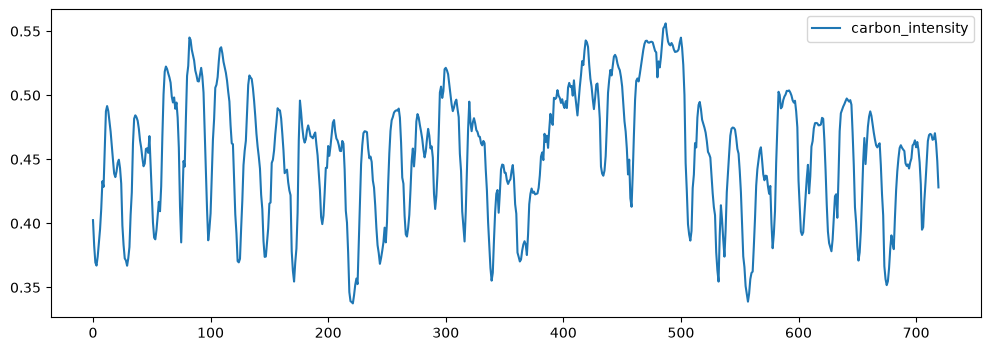

In [8]:
carbon = pd.read_csv("./data/carbon_intensity.csv")

carbon.plot(figsize=(12, 4))

Here, Carbon Intensity means "How much CO₂ is emitted for each unit of electricity taken from the grid."

Carbon Intensity changes over time because the electricity grid uses different mixes of generation sources. For example, if more low-carbon electricity is available, carbon intensity may be lower; when more fossil-fuel generation is supplying the grid, it may be higher.

For example, at low carbon intensity ( 0.35 C02/kwh), to charge battery. At high carbon intensity (0.55 co2/kwh) to dischange battery to avoid buying as much high-carbon grid electricity.

So, the design of the agent is not necessarily trying to use less electricity at all times. It may instead try to shift when electricity is drawn from the grid, so more consumption occurs during lower-carbon periods and less during higher-carbon periods.